# Olist E-commerce Performance Analysis

This analysis evaluates marketplace performance across commercial value, delivery reliability, customer satisfaction, and repeat purchasing. The workflow moves from data-quality checks to headline KPIs, monthly revenue, and operational diagnostics so that business performance is interpreted alongside the customer experience.

In [1]:
import pandas as pd, glob, os

dfs = {}
for f in glob.glob("../data/*.csv"):
    name = os.path.basename(f).replace("olist_", "").replace("_dataset.csv", "").replace(".csv", "")
    dfs[name] = pd.read_csv(f)

print(list(dfs.keys()))

['customers', 'geolocation', 'orders', 'order_items', 'order_payments', 'order_reviews', 'products', 'sellers', 'product_category_name_translation']


In [2]:
globals().update(dfs)

In [3]:
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
"order_delivered_customer_date", "order_estimated_delivery_date"]
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])

In [4]:
orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

## Defining the delivery outcome

Delivery reliability is measured only on delivered orders with a recorded customer-delivery timestamp. An order is classified as late when the actual delivery date exceeds the promised date; this avoids treating cancellations or orders without a final outcome as delivery failures.

In [5]:
delivered = orders[orders.order_status == "delivered"].dropna(
    subset=["order_delivered_customer_date"]).copy()
delivered["is_late"] = (delivered.order_delivered_customer_date >
    delivered.order_estimated_delivery_date).astype(int)
delivered["delay_days"] = (delivered.order_delivered_customer_date -
    delivered.order_estimated_delivery_date).dt.days

## Establishing the KPI scorecard

The scorecard combines product revenue, payment-based average order value, on-time delivery, review score, and customer repeat rate. These measures are intentionally complementary: revenue and order value describe commercial scale, while delivery, reviews, and repeat purchasing indicate whether that scale is supported by a healthy customer experience.

In [6]:
#Total Revenue
revenue = order_items.price.sum()
#Total Payment Value per Order
order_pay = order_payments.groupby("order_id").payment_value.sum()
#Average Order Value
aov = order_pay.mean()
#On-Time Delivery Rate
on_time = 1 - delivered.is_late.mean()
#Average Customer Review Score
avg_score = order_reviews.review_score.mean()
#Calculate the repeat rate
orders_per_cust = customers.groupby("customer_unique_id").size()
repeat_rate = (orders_per_cust > 1).mean()
#Monthly Metrics
monthly = (delivered.assign(month=delivered.order_purchase_timestamp.dt.to_period("M"))
.groupby("month").agg(orders=("order_id", "count"), late_rate=("is_late", "mean")))
monthly["late_rate_pct"] = monthly["late_rate"] * 100

In [7]:
print(f"Total Revenue: ${revenue:,.2f}")
print(f"Average Order Value: ${aov:,.2f}")
print(f"Average Order Value: ${aov:,.2f}")
print(f"On-Time Delivery Rate: {on_time:.2%}")
print(f"Average Customer Review Score: {avg_score:.2f}")
print(f"Customer Repeat Rate: {repeat_rate:.2%}")
print("\nMonthly Metrics:")
print(monthly)

Total Revenue: $13,591,643.70
Average Order Value: $160.99
Average Order Value: $160.99
On-Time Delivery Rate: 91.89%
Average Customer Review Score: 4.09
Customer Repeat Rate: 3.12%

Monthly Metrics:
         orders  late_rate  late_rate_pct
month                                    
2016-09       1   1.000000     100.000000
2016-10     265   0.011321       1.132075
2016-12       1   0.000000       0.000000
2017-01     750   0.030667       3.066667
2017-02    1653   0.032063       3.206292
2017-03    2546   0.055774       5.577376
2017-04    2303   0.078593       7.859314
2017-05    3545   0.036107       3.610719
2017-06    3135   0.038596       3.859649
2017-07    3872   0.034349       3.434917
2017-08    4193   0.033150       3.315049
2017-09    4150   0.052048       5.204819
2017-10    4478   0.052925       5.292541
2017-11    7288   0.143112      14.311196
2017-12    5513   0.083802       8.380192
2018-01    7069   0.065639       6.563870
2018-02    6555   0.159878      15.987796
20

#  E-commerce Performance Insights

## Executive Summary

| KPI | Result |
|---|---:|
|  Total product revenue | **$13.59M** |
|  Average order value | **$160.99** |
|  On-time delivery rate | **91.89%** |
|  Average review score | **4.09 / 5** |
|  Customer repeat rate | **3.12%** |

## Key Insights

- **Strong revenue performance:** The business generated **$13.59M** in product sales.
- **Delivery is generally reliable:** More than **9 out of 10 orders arrived on time**.
- **Delivery delays require attention:** Late deliveries peaked in **March 2018 at 21.36%**, followed by **February 2018 at 15.99%**.
- **Customer satisfaction is positive:** The average rating of **4.09/5** indicates generally favorable customer experiences.
- **Customer retention is the main opportunity:** Only **3.12% of customers placed repeat orders**, suggesting limited loyalty and significant potential for retention initiatives.

## Recommended Actions

1. Investigate logistics capacity and carrier performance during **February–March peaks**.
2. Introduce loyalty rewards, personalized offers, and post-purchase campaigns to increase repeat purchases.
3. Monitor low-rated reviews alongside late deliveries to identify service issues.
4. Use the **$160.99 average order value** as a benchmark for bundles and upselling strategies.

The results show **$13.59M** in product revenue, a **$160.99** average order value, **91.89%** on-time delivery, a **4.09/5** average review score, and a **3.12%** repeat rate. The strongest immediate tension is between positive average satisfaction and limited repeat purchasing; repeat rate should be investigated further by cohort, category, and acquisition channel rather than inferred from the aggregate alone.

In [8]:
sales = order_items.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id"
)

sales["order_purchase_timestamp"] = pd.to_datetime(
    sales["order_purchase_timestamp"]
)

monthly_revenue = sales.groupby(
    sales.order_purchase_timestamp.dt.to_period("M")
).price.sum()

## Monthly revenue trend

Revenue is recomputed at the order-item level and grouped by purchase month. This preserves the commercial grain of the sales data and makes changes in demand visible over time before comparing them with delivery and customer metrics.

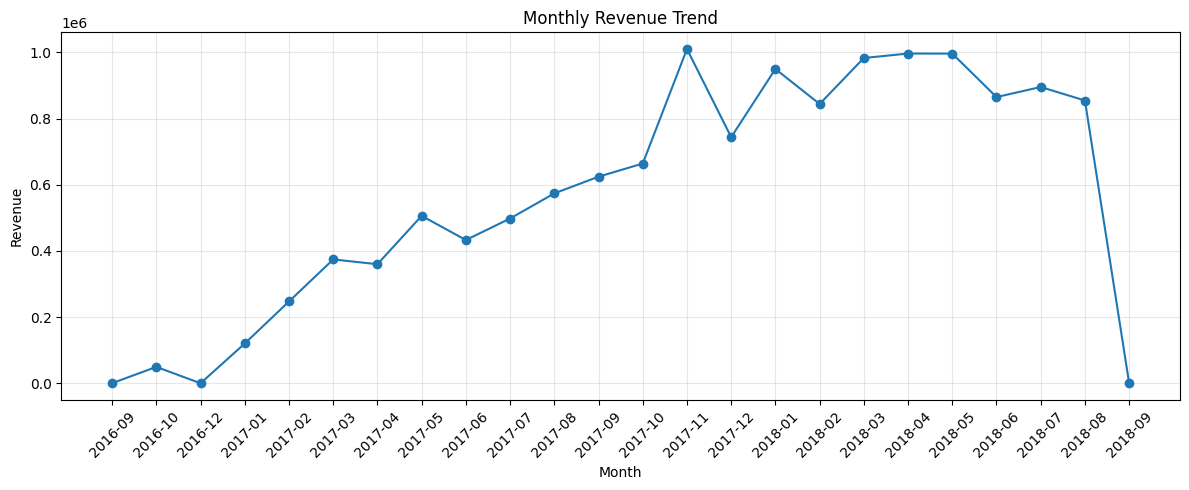

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

The revenue chart provides a demand baseline for interpreting operational pressure. Peaks should be compared with the monthly late-rate table rather than treated as evidence of a cause: the notebook is descriptive and does not isolate the effect of order volume from carrier, seller, or seasonal factors.

In [10]:
rev = order_reviews.groupby("order_id").review_score.mean().rename("score").reset_index()
d = delivered.merge(rev, on="order_id")
gap = d[d.is_late == 0].score.mean() - d[d.is_late == 1].score.mean()
print(d.groupby("is_late").score.mean(), "gap:", round(gap, 2))
late_items = order_items[["order_id", "seller_id"]].drop_duplicates().merge(
 delivered[["order_id", "is_late"]], on="order_id")
by_seller = late_items.groupby("seller_id").is_late.sum().sort_values(ascending=False)
top_n = int(len(by_seller) * 0.10)
share = by_seller.head(top_n).sum() / by_seller.sum()
print(f"Top 10% of sellers cause {share:.0%} of late orders")

is_late
0    4.294292
1    2.566506
Name: score, dtype: float64 gap: 1.73
Top 10% of sellers cause 73% of late orders


## Linking delivery performance to customer experience

Review scores are joined to delivered orders to compare customer sentiment for late and on-time deliveries. The seller analysis then measures how concentrated late-order volume is among the highest-volume contributors, helping distinguish a broad platform issue from a smaller operational concentration.

Late deliveries are associated with a **2.57** average review score versus **4.29** for on-time deliveries, a **1.73-point** gap. The top 10% of sellers account for **73% of late orders**, indicating that seller-level investigation may be more actionable than a platform-wide response; because the calculation uses late-order counts, seller volume and seller-specific rates should be reviewed before decisions are made.